# SAMS Vision: Safe and Unsafe Behaviour Classification

**Status: exploratory study, not served by the live system.** SAMS (Smart Accident Monitoring System) watches a worker near a machine through person detection, PPE, distance, pose and fall detection. This notebook asks a broader question: can a single camera frame be classified directly as a safe or unsafe workplace behaviour? It trains six image classifiers on a public dataset and measures how far whole-frame classification gets. The promoted weights are kept in `models/vision/safe_unsafe/` for reference, but no live service loads them.

## Dataset

[Voxel51/Safe_and_Unsafe_Behaviours](https://huggingface.co/datasets/Voxel51/Safe_and_Unsafe_Behaviours): 691 short 1080p clips filmed in one industrial facility, with a published train/test split (566 / 125 clips). The eight classes form four contrasting pairs, each with a safe and an unsafe version of the same activity:

| Activity | SAFE | UNSAFE |
|---|---|---|
| Moving around the floor | Safe Walkway | Safe Walkway Violation |
| Working on equipment | Authorized Intervention | Unauthorized Intervention |
| Electrical panels | Closed Panel Cover | Opened Panel Cover |
| Moving loads | Safe Carrying | Carrying Overload with Forklift |

The classes are imbalanced: from 210 clips (Safe Walkway Violation) down to 30 (Safe Carrying).

## Method and reasoning

1. **Frames from clips.** Each clip contributes a few evenly spaced frames. Neighbouring frames of one clip are nearly identical, so more frames per clip would add little new information.
2. **Leakage-free splits.** All frames of a clip stay in one split. The published test clips are used only for the final measurement. Validation clips are drawn from the training clips, 15 % per class, so even the rarest class is represented.
3. **A ladder of experiments.** A small CNN trained from scratch sets the floor. Frozen ImageNet backbones (ResNet18, EfficientNet-B0, MobileNetV3-Small) test how far generic features go. Full fine-tuning (ResNet18) tests adapting the features to this domain. A robust variant (EfficientNet-B0 with class-weighted loss and strong augmentation) targets the class imbalance.
4. **Selection on validation only.** Each run keeps the epoch with the best validation macro-F1 and stops early when it stops improving. The winner is the experiment with the best validation macro-F1. Test metrics are reported for every experiment but never used to choose.
5. **Two levels of evaluation.** Eight-class macro-F1 measures how well the classifier tells the behaviours apart. Grouping the predictions into SAFE and UNSAFE measures what SAMS would actually use, and **unsafe recall** (the share of unsafe frames caught) is the headline safety number.

## Sections

| § | Content |
|---|---|
| 0 | Setup: paths, packages, configuration, helpers |
| 1 | Dataset metadata and class list |
| 2 | Exploratory data analysis |
| 3 | Frame extraction, cached on Drive |
| 4 | Data pipeline, models and training utilities; embedding check |
| 5 | Experiments |
| 6 | Comparison, promotion and SAFE/UNSAFE evaluation |
| 7 | Findings, limitations and relevance to SAMS |

## Outputs

| Path | Content |
|---|---|
| `models/vision/safe_unsafe/<experiment_id>/` | Weights, metadata, history, classification report and confusion matrix of each experiment |
| `models/vision/safe_unsafe/best.pt`, `metadata.json`, `model_card.md` | The promoted experiment |
| `results/vision/safe_unsafe/` | Every table as CSV and every chart as PNG |
| `datasets/vision/safe_unsafe/frames_*.zip` (Drive) | Extracted frames, so later sessions skip the video download |

## Conventions

- The notebook runs top to bottom with no run flags; every setting lives in Section 0.3.
- Every table is displayed and saved as CSV; every chart is saved as PNG.
- Seeds are fixed. GPU kernels are not fully deterministic, so a re-run can differ in the second decimal.

## 0. Setup

### 0.1 Paths

In Colab, the dataset and extracted frames live on the VM's local disk (`/content/SAMS`) for fast reading during training. Models, results and the frame cache live on Google Drive (`MyDrive/SAMS`) so they survive the session. Locally, the repository root plays the role of Drive.

In [1]:
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

if IN_COLAB:
    from google.colab import drive

    drive.mount("/content/drive")
    SAMS_ROOT = Path("/content/SAMS")
    DRIVE_ROOT = Path("/content/drive/MyDrive/SAMS")
else:
    SAMS_ROOT = Path("./SAMS_runtime")
    here = Path.cwd().resolve()
    DRIVE_ROOT = next((p for p in (here, here.parent) if (p / "manage.py").exists()), Path("./SAMS_drive_mirror"))

DATA_DIR = SAMS_ROOT / "datasets" / "vision" / "safe_unsafe"
SNAPSHOT_DIR = DATA_DIR / "hf_snapshot"
FRAMES_DIR = DATA_DIR / "frames"
CACHE_DIR = DRIVE_ROOT / "datasets" / "vision" / "safe_unsafe"
MODELS_DIR = DRIVE_ROOT / "models" / "vision" / "safe_unsafe"
RESULTS_DIR = DRIVE_ROOT / "results" / "vision" / "safe_unsafe"
for folder in (DATA_DIR, SNAPSHOT_DIR, FRAMES_DIR, CACHE_DIR, MODELS_DIR, RESULTS_DIR):
    folder.mkdir(parents=True, exist_ok=True)

for name in ("DATA_DIR", "CACHE_DIR", "MODELS_DIR", "RESULTS_DIR"):
    print(f"{name:12s}", globals()[name])

Running in Colab: True
Mounted at /content/drive
DATA_DIR     /content/SAMS/datasets/vision/safe_unsafe
CACHE_DIR    /content/drive/MyDrive/SAMS/datasets/vision/safe_unsafe
MODELS_DIR   /content/drive/MyDrive/SAMS/models/vision/safe_unsafe
RESULTS_DIR  /content/drive/MyDrive/SAMS/results/vision/safe_unsafe


### 0.2 Packages

In [2]:
import subprocess
import sys

PACKAGES = [
    "pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "torch", "torchvision",
    "tqdm", "Pillow", "opencv-python-headless", "huggingface_hub",
]
if IN_COLAB:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *PACKAGES])
    print("Packages installed.")
else:
    print("Not in Colab. Install these packages if an import fails:", PACKAGES)

Packages installed.


In [3]:
import gc
import json
import random
import shutil
import time
import warnings
from datetime import datetime, timezone
from typing import Any, Dict, List, Optional, Tuple

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
from IPython.display import display
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

### 0.3 Configuration

Every setting that changes the result is set here and listed with its meaning. Change a value and rerun from this cell downward.

In [4]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HF_REPO = "Voxel51/Safe_and_Unsafe_Behaviours"
MAX_FRAMES_PER_VIDEO = 3
FRAME_MAX_SIDE = 640
VAL_FRACTION = 0.15

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2
PATIENCE = 4

EPOCHS_SCRATCH = 12
EPOCHS_FROZEN = 8
EPOCHS_FINETUNE = 10
LR_HEAD = 1e-3
LR_FINETUNE = 3e-5
WEIGHT_DECAY = 1e-4

UNSAFE_CLASSES = {
    "Safe Walkway Violation",
    "Unauthorized Intervention",
    "Opened Panel Cover",
    "Carrying Overload with Forklift",
}
SAFE_CLASSES = {"Safe Walkway", "Authorized Intervention", "Closed Panel Cover", "Safe Carrying"}

config_table = pd.DataFrame([
    {"setting": "SEED", "value": SEED, "meaning": "Seed for Python, NumPy and PyTorch"},
    {"setting": "DEVICE", "value": str(DEVICE), "meaning": "Training device"},
    {"setting": "MAX_FRAMES_PER_VIDEO", "value": MAX_FRAMES_PER_VIDEO, "meaning": "Evenly spaced frames taken from each clip"},
    {"setting": "FRAME_MAX_SIDE", "value": FRAME_MAX_SIDE, "meaning": "Longest side of a stored frame in pixels (1080p is downscaled)"},
    {"setting": "VAL_FRACTION", "value": VAL_FRACTION, "meaning": "Share of each class's training clips held out for validation"},
    {"setting": "IMG_SIZE", "value": IMG_SIZE, "meaning": "Network input size (square)"},
    {"setting": "BATCH_SIZE", "value": BATCH_SIZE, "meaning": "Frames per training step"},
    {"setting": "PATIENCE", "value": PATIENCE, "meaning": "Epochs without a better validation macro-F1 before stopping"},
    {"setting": "EPOCHS_SCRATCH", "value": EPOCHS_SCRATCH, "meaning": "Epoch limit, CNN from scratch"},
    {"setting": "EPOCHS_FROZEN", "value": EPOCHS_FROZEN, "meaning": "Epoch limit, frozen backbones"},
    {"setting": "EPOCHS_FINETUNE", "value": EPOCHS_FINETUNE, "meaning": "Epoch limit, full fine-tuning"},
    {"setting": "LR_HEAD", "value": LR_HEAD, "meaning": "AdamW learning rate when only a new head (or a small CNN) trains"},
    {"setting": "LR_FINETUNE", "value": LR_FINETUNE, "meaning": "AdamW learning rate when pretrained layers train too"},
    {"setting": "WEIGHT_DECAY", "value": WEIGHT_DECAY, "meaning": "AdamW weight decay"},
]).set_index("setting")
config_table.to_csv(RESULTS_DIR / "config.csv")
display(config_table)

,value,meaning
setting,,
SEED,42,"Seed for Python, NumPy and PyTorch"
DEVICE,cuda,Training device
MAX_FRAMES_PER_VIDEO,3,Evenly spaced frames taken from each clip
FRAME_MAX_SIDE,640,Longest side of a stored frame in pixels (1080...
VAL_FRACTION,0.15,Share of each class's training clips held out ...
IMG_SIZE,224,Network input size (square)
BATCH_SIZE,32,Frames per training step
PATIENCE,4,Epochs without a better validation macro-F1 be...
EPOCHS_SCRATCH,12,"Epoch limit, CNN from scratch"


### 0.4 Helpers

In [5]:
def save_table(frame: pd.DataFrame, name: str) -> Path:
    path = RESULTS_DIR / f"{name}.csv"
    frame.to_csv(path)
    display(frame)
    return path


def save_figure(name: str) -> None:
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"{name}.png", dpi=140, bbox_inches="tight")
    plt.show()


def to_json_safe(value):
    """Turn NumPy values into plain Python types that json can write."""
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, Path):
        return str(value)
    raise TypeError(f"Object of type {type(value).__name__} is not JSON serializable")


HYPERPARAMS: Dict[str, pd.DataFrame] = {}


def register_hyperparams(exp_id: str, rows: List[Dict[str, Any]]) -> None:
    frame = pd.DataFrame(rows)
    HYPERPARAMS[exp_id] = frame
    save_table(frame.set_index("parameter"), f"hyperparams_{exp_id}")

## 1. Dataset metadata and class list

Only `samples.json` is downloaded here: it lists every clip with its label, split tag and video properties. The videos themselves (several GB) are needed only when frames have to be extracted (Section 3), so a session that finds the frame cache on Drive never downloads them.

In [6]:
from huggingface_hub import snapshot_download

snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=str(SNAPSHOT_DIR), allow_patterns=["samples.json"])
with open(SNAPSHOT_DIR / "samples.json") as f:
    samples_blob = json.load(f)
raw_samples = samples_blob["samples"] if isinstance(samples_blob, dict) else samples_blob

rows = []
for sample in raw_samples:
    tags = sample.get("tags") or []
    md_ = sample.get("metadata") or {}
    rows.append({
        "video": Path(sample["filepath"]).stem,
        "relpath": sample["filepath"],
        "label": (sample.get("ground_truth") or {}).get("label"),
        "split": "train" if "train" in tags else ("test" if "test" in tags else "unknown"),
        "duration_s": md_.get("duration"),
        "fps": md_.get("frame_rate"),
        "width": md_.get("frame_width"),
        "height": md_.get("frame_height"),
    })
meta_df = pd.DataFrame(rows)
meta_df = meta_df[meta_df["label"].notna() & meta_df["split"].isin(["train", "test"])].reset_index(drop=True)

CLASS_NAMES = sorted(meta_df["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
label_to_idx = {c: i for i, c in enumerate(CLASS_NAMES)}
unknown = set(CLASS_NAMES) - UNSAFE_CLASSES - SAFE_CLASSES
assert not unknown, f"Classes missing from the SAFE/UNSAFE grouping: {unknown}"
UNSAFE_IDX = np.array([label_to_idx[c] for c in CLASS_NAMES if c in UNSAFE_CLASSES])
meta_df["group"] = np.where(meta_df["label"].isin(UNSAFE_CLASSES), "UNSAFE", "SAFE")

print("Clips:", len(meta_df), "| classes:", NUM_CLASSES)
save_table(
    pd.DataFrame({"class": CLASS_NAMES, "index": range(NUM_CLASSES), "group": ["UNSAFE" if c in UNSAFE_CLASSES else "SAFE" for c in CLASS_NAMES]}).set_index("class"),
    "class_list",
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

Clips: 691 | classes: 8


,index,group
class,,
Authorized Intervention,0,SAFE
Carrying Overload with Forklift,1,UNSAFE
Closed Panel Cover,2,SAFE
Opened Panel Cover,3,UNSAFE
Safe Carrying,4,SAFE
Safe Walkway,5,SAFE
Safe Walkway Violation,6,UNSAFE
Unauthorized Intervention,7,UNSAFE


PosixPath('/content/drive/MyDrive/SAMS/results/vision/safe_unsafe/class_list.csv')

## 2. Exploratory data analysis

Clip counts per class and split, and clip durations. Two things matter for the experiments. First, the imbalance: the largest class has about seven times as many clips as the smallest, which is why selection uses macro-F1 (every class counts equally) rather than accuracy. Second, how few test clips the rare classes have: a class with 8 test clips gives 24 test frames, so its per-class scores move in large steps.

split,test,train,total,group
label,,,,
Safe Walkway Violation,32,178,210,UNSAFE
Opened Panel Cover,13,129,142,UNSAFE
Unauthorized Intervention,11,97,108,UNSAFE
Safe Walkway,25,50,75,SAFE
Carrying Overload with Forklift,8,48,56,UNSAFE
Authorized Intervention,15,23,38,SAFE
Closed Panel Cover,13,19,32,SAFE
Safe Carrying,8,22,30,SAFE


,mean,min,max
label,,,
Authorized Intervention,9.2,4.1,15.0
Carrying Overload with Forklift,6.9,3.0,13.0
Closed Panel Cover,4.9,1.4,10.5
Opened Panel Cover,5.8,2.6,12.0
Safe Carrying,7.4,2.1,12.1
Safe Walkway,9.5,4.0,20.8
Safe Walkway Violation,9.7,5.0,17.0
Unauthorized Intervention,10.3,7.0,20.8


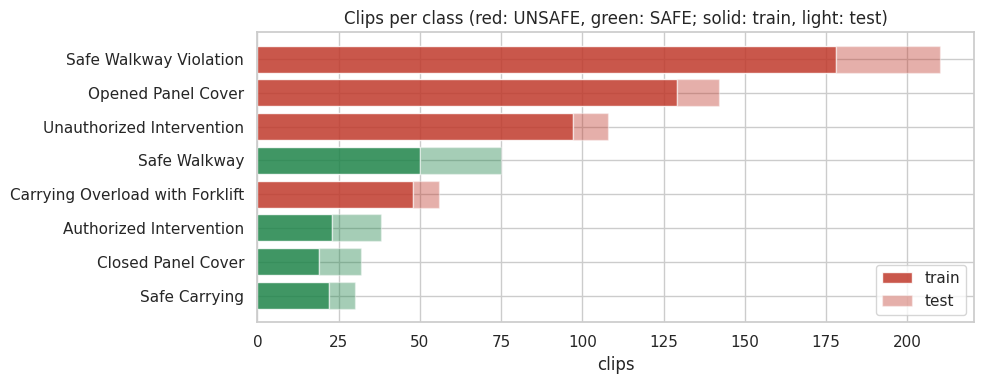

In [7]:
counts = pd.crosstab(meta_df["label"], meta_df["split"]).reindex(CLASS_NAMES)
counts["total"] = counts.sum(axis=1)
counts["group"] = ["UNSAFE" if c in UNSAFE_CLASSES else "SAFE" for c in counts.index]
save_table(counts.sort_values("total", ascending=False), "eda_clips_by_class_and_split")
save_table(meta_df.groupby("label")["duration_s"].describe()[["mean", "min", "max"]].round(1), "eda_clip_durations_s")

fig, ax = plt.subplots(figsize=(10, 4))
order = counts.sort_values("total", ascending=False).index
colors = ["#c0392b" if c in UNSAFE_CLASSES else "#1e8449" for c in order]
ax.barh(order, counts.loc[order, "train"], color=colors, alpha=0.85, label="train")
ax.barh(order, counts.loc[order, "test"], left=counts.loc[order, "train"], color=colors, alpha=0.4, label="test")
ax.invert_yaxis()
ax.set_xlabel("clips")
ax.set_title("Clips per class (red: UNSAFE, green: SAFE; solid: train, light: test)")
ax.legend()
save_figure("eda_clips_per_class")

## 3. Frame extraction

`MAX_FRAMES_PER_VIDEO` evenly spaced frames are taken from every clip, downscaled so the longest side is `FRAME_MAX_SIDE` pixels (the network sees 224 × 224 anyway), and written to `frames/<split>/<class>/`. A manifest records each frame's clip, label and split.

The frames are zipped to Drive. A later session restores them from the zip and never downloads the videos again. The zip's name includes the extraction settings, so changing a setting extracts the frames afresh.

In [8]:
FRAME_CACHE = CACHE_DIR / f"frames_{MAX_FRAMES_PER_VIDEO}x{FRAME_MAX_SIDE}.zip"
manifest_path = FRAMES_DIR / "manifest.csv"


def extract_frames(video_path: Path, out_dir: Path, stem: str) -> List[Path]:
    """Up to MAX_FRAMES_PER_VIDEO evenly spaced frames, longest side FRAME_MAX_SIDE."""
    cap = cv2.VideoCapture(str(video_path))
    if not cap.isOpened():
        return []
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT) or 0)
    if total <= 0:
        cap.release()
        return []
    out_dir.mkdir(parents=True, exist_ok=True)
    saved = []
    for j, index in enumerate(np.linspace(0, total - 1, num=min(MAX_FRAMES_PER_VIDEO, total), dtype=int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, int(index))
        ok, frame = cap.read()
        if not ok:
            continue
        scale = FRAME_MAX_SIDE / max(frame.shape[:2])
        if scale < 1:
            frame = cv2.resize(frame, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
        path = out_dir / f"{stem}_f{j:02d}.jpg"
        cv2.imwrite(str(path), frame, [cv2.IMWRITE_JPEG_QUALITY, 92])
        saved.append(path)
    cap.release()
    return saved


if manifest_path.exists() and "relpath" not in pd.read_csv(manifest_path, nrows=1).columns:
    print("Frames from an older extraction format: extracting again.")
    shutil.rmtree(FRAMES_DIR)
    FRAMES_DIR.mkdir(parents=True)

if not manifest_path.exists() and FRAME_CACHE.exists():
    print("Restoring frames from", FRAME_CACHE)
    shutil.unpack_archive(str(FRAME_CACHE), str(FRAMES_DIR))

if not manifest_path.exists():
    print("No frame cache: downloading the videos (several GB) and extracting frames.")
    snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=str(SNAPSHOT_DIR), allow_patterns=["data/*"])
    records = []
    for row in tqdm(meta_df.itertuples(), total=len(meta_df), desc="Extracting"):
        out_dir = FRAMES_DIR / row.split / row.label.replace(" ", "_")
        for path in extract_frames(SNAPSHOT_DIR / row.relpath, out_dir, row.video):
            records.append({"relpath": str(path.relative_to(FRAMES_DIR)), "video": row.video, "split": row.split, "label": row.label})
    pd.DataFrame(records).to_csv(manifest_path, index=False)
    print("Caching frames to", FRAME_CACHE)
    shutil.make_archive(str(FRAME_CACHE.with_suffix("")), "zip", str(FRAMES_DIR))

frame_manifest = pd.read_csv(manifest_path)
frame_manifest["filepath"] = frame_manifest["relpath"].map(lambda p: str(FRAMES_DIR / p))
frame_manifest["label_idx"] = frame_manifest["label"].map(label_to_idx)
missing_clips = sorted(set(meta_df["video"]) - set(frame_manifest["video"]))
print(f"Frames: {len(frame_manifest)} from {frame_manifest['video'].nunique()} clips; clips with no readable frame: {len(missing_clips)}")
save_table(frame_manifest.groupby(["split", "label"]).size().unstack(0).reindex(CLASS_NAMES), "frames_by_class_and_split")

No frame cache: downloading the videos (several GB) and extracting frames.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 691 files:   0%|          | 0/691 [00:00<?, ?it/s]

Extracting:   0%|          | 0/691 [00:00<?, ?it/s]

Caching frames to /content/drive/MyDrive/SAMS/datasets/vision/safe_unsafe/frames_3x640.zip
Frames: 2059 from 691 clips; clips with no readable frame: 0


split,test,train
label,,
Authorized Intervention,45,68
Carrying Overload with Forklift,24,144
Closed Panel Cover,38,57
Opened Panel Cover,39,387
Safe Carrying,24,66
Safe Walkway,73,148
Safe Walkway Violation,93,530
Unauthorized Intervention,33,290


PosixPath('/content/drive/MyDrive/SAMS/results/vision/safe_unsafe/frames_by_class_and_split.csv')

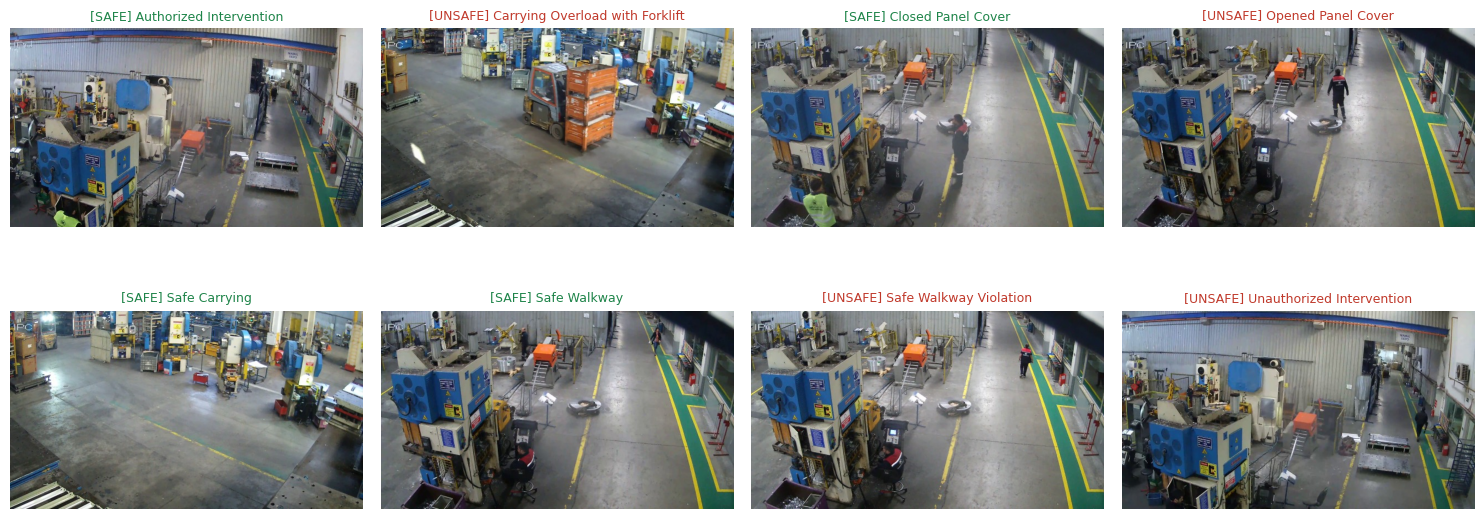

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6.5))
for ax, cls in zip(axes.ravel(), CLASS_NAMES):
    row = frame_manifest[(frame_manifest["label"] == cls) & (frame_manifest["split"] == "train")].sample(1, random_state=SEED).iloc[0]
    ax.imshow(Image.open(row["filepath"]).convert("RGB"))
    unsafe = cls in UNSAFE_CLASSES
    ax.set_title(f"[{'UNSAFE' if unsafe else 'SAFE'}] {cls}", fontsize=9, color="#c0392b" if unsafe else "#1e8449")
    ax.axis("off")
save_figure("eda_class_gallery")

## 4. Data pipeline, models and training utilities

### 4.1 Splits and loaders

**Splits.** The published test clips form the test set. From the training clips, `VAL_FRACTION` of each class's clips (at least one) is held out for validation. All frames of a clip stay in the same split, so no near-identical frame can appear on both sides.

**Transforms.** Every frame is resized to 224 × 224 and normalised with the ImageNet statistics the pretrained backbones expect. Training adds a horizontal flip. The robust experiment uses stronger augmentation: random crops, colour jitter and small rotations, which imitate camera placement and lighting changes.

In [10]:
NORMALIZE = transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
train_tfms = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.RandomHorizontalFlip(), transforms.ToTensor(), NORMALIZE])
strong_train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE + 32, IMG_SIZE + 32)),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.25, contrast=0.25, saturation=0.2),
    transforms.RandomRotation(12),
    transforms.ToTensor(),
    NORMALIZE,
])
eval_tfms = transforms.Compose([transforms.Resize((IMG_SIZE, IMG_SIZE)), transforms.ToTensor(), NORMALIZE])


class FrameDataset(Dataset):
    def __init__(self, df: pd.DataFrame, transform):
        self.paths = df["filepath"].tolist()
        self.labels = df["label_idx"].astype(int).tolist()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.paths)

    def __getitem__(self, idx: int):
        return self.transform(Image.open(self.paths[idx]).convert("RGB")), self.labels[idx]


def split_frames(manifest: pd.DataFrame) -> Dict[str, pd.DataFrame]:
    """Test = published test clips. Validation = VAL_FRACTION of each class's training clips."""
    train_all = manifest[manifest["split"] == "train"]
    rng = np.random.default_rng(SEED)
    val_videos = set()
    for _cls, clips in train_all.groupby("label")["video"]:
        videos = sorted(clips.unique())
        n_val = max(1, int(round(VAL_FRACTION * len(videos))))
        val_videos.update(rng.choice(videos, size=n_val, replace=False))
    return {
        "train": train_all[~train_all["video"].isin(val_videos)].reset_index(drop=True),
        "val": train_all[train_all["video"].isin(val_videos)].reset_index(drop=True),
        "test": manifest[manifest["split"] == "test"].reset_index(drop=True),
    }


def make_loaders(frames: Dict[str, pd.DataFrame], train_transform) -> Dict[str, DataLoader]:
    generator = torch.Generator().manual_seed(SEED)
    pin = torch.cuda.is_available()
    return {
        "train": DataLoader(FrameDataset(frames["train"], train_transform), batch_size=BATCH_SIZE, shuffle=True,
                            generator=generator, num_workers=NUM_WORKERS, pin_memory=pin),
        "val": DataLoader(FrameDataset(frames["val"], eval_tfms), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
        "test": DataLoader(FrameDataset(frames["test"], eval_tfms), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin),
    }


FRAMES = split_frames(frame_manifest)
base_loaders = make_loaders(FRAMES, train_tfms)
split_table = pd.DataFrame({
    f"{split} {unit}": frame.groupby("label")["video"].nunique() if unit == "clips" else frame.groupby("label").size()
    for split, frame in FRAMES.items()
    for unit in ("clips", "frames")
}).reindex(CLASS_NAMES).fillna(0).astype(int)
split_table.loc["total"] = split_table.sum()
save_table(split_table, "split_by_class")
assert not (set(FRAMES["train"]["video"]) & set(FRAMES["val"]["video"])), "A clip is in both train and val"

,train clips,train frames,val clips,val frames,test clips,test frames
label,,,,,,
Authorized Intervention,20,59,3,9,15,45
Carrying Overload with Forklift,41,123,7,21,8,24
Closed Panel Cover,16,48,3,9,13,38
Opened Panel Cover,110,330,19,57,13,39
Safe Carrying,19,57,3,9,8,24
Safe Walkway,42,125,8,23,25,73
Safe Walkway Violation,151,449,27,81,32,93
Unauthorized Intervention,82,245,15,45,11,33
total,481,1436,85,254,125,369


### 4.2 Embedding check

Before training, a frozen ImageNet ResNet18 embeds up to 20 training frames per class, and the embeddings are projected onto two principal components. Classes that already cluster here need little adaptation. Classes that overlap need the network to learn features specific to this domain, which is what fine-tuning offers.

/tmp/ipykernel_3373/1148592011.py:13: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pca_frames = FRAMES["train"].groupby("label", group_keys=False).apply(lambda f: f.sample(min(20, len(f)), random_state=SEED))


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 171MB/s]


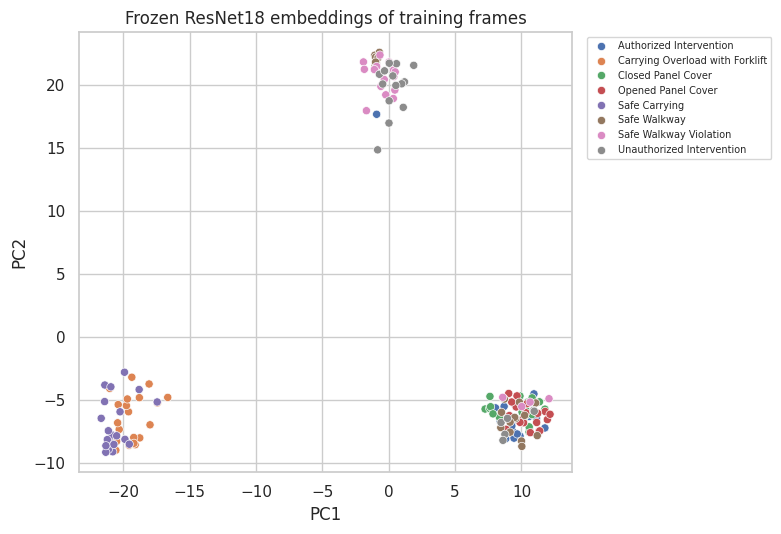

In [11]:
@torch.no_grad()
def embed_frames(paths: List[str]) -> np.ndarray:
    trunk = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    trunk.fc = nn.Identity()
    trunk = trunk.to(DEVICE).eval()
    vectors = []
    for start in range(0, len(paths), BATCH_SIZE):
        batch = torch.stack([eval_tfms(Image.open(p).convert("RGB")) for p in paths[start : start + BATCH_SIZE]])
        vectors.append(trunk(batch.to(DEVICE)).cpu().numpy())
    return np.concatenate(vectors)


pca_frames = FRAMES["train"].groupby("label", group_keys=False).apply(lambda f: f.sample(min(20, len(f)), random_state=SEED))
coords = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(embed_frames(pca_frames["filepath"].tolist())))
fig, ax = plt.subplots(figsize=(8, 5.5))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=pca_frames["label"].values, hue_order=CLASS_NAMES, s=35, ax=ax)
ax.set(xlabel="PC1", ylabel="PC2", title="Frozen ResNet18 embeddings of training frames")
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
save_figure("pca_resnet18_embeddings")

### 4.3 Models

| Builder | Backbone | Trainable part |
|---|---|---|
| `TinyCNN` | 4 conv blocks, no pretraining | Everything |
| `build_resnet18` | ResNet18, ImageNet | New head only (frozen) or everything (fine-tune) |
| `build_efficientnet_b0` | EfficientNet-B0, ImageNet | New head only (frozen) or everything (fine-tune) |
| `build_mobilenet_v3_small` | MobileNetV3-Small, ImageNet | New head only; the smallest model, suited to edge devices |

In [12]:
class TinyCNN(nn.Module):
    """Small CNN trained from scratch: the baseline that shows what pretraining adds."""

    def __init__(self, num_classes: int):
        super().__init__()
        blocks = []
        for c_in, c_out, pool in ((3, 32, True), (32, 64, True), (64, 128, True), (128, 256, False)):
            blocks += [nn.Conv2d(c_in, c_out, 3, padding=1), nn.BatchNorm2d(c_out), nn.ReLU(inplace=True)]
            if pool:
                blocks.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*blocks, nn.AdaptiveAvgPool2d(1))
        self.classifier = nn.Sequential(nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, num_classes))

    def forward(self, x):
        return self.classifier(self.features(x))


def _freeze(model: nn.Module, freeze_backbone: bool) -> nn.Module:
    if freeze_backbone:
        for p in model.parameters():
            p.requires_grad = False
    return model


def build_resnet18(num_classes: int, freeze_backbone: bool) -> nn.Module:
    model = _freeze(models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1), freeze_backbone)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


def build_efficientnet_b0(num_classes: int, freeze_backbone: bool) -> nn.Module:
    model = _freeze(models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1), freeze_backbone)
    model.classifier[1] = nn.Linear(model.classifier[1].in_features, num_classes)
    return model


def build_mobilenet_v3_small(num_classes: int, freeze_backbone: bool) -> nn.Module:
    model = _freeze(models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.IMAGENET1K_V1), freeze_backbone)
    model.classifier[3] = nn.Linear(model.classifier[3].in_features, num_classes)
    return model

### 4.4 Training and evaluation

`train_one_experiment` trains with AdamW and a cosine learning-rate schedule. After each epoch it scores the validation set and keeps the weights of the best validation macro-F1. It stops once `PATIENCE` epochs pass without improvement. The test set is scored once, with the kept weights.

`compute_metrics` reports the eight-class metrics and the SAFE/UNSAFE view, in which a prediction counts as correct when it falls in the right group. `save_experiment` writes weights, metadata, history, report and confusion matrix, and records one row in the experiment ledger.

In [13]:
def compute_metrics(y_true: np.ndarray, y_pred: np.ndarray) -> Dict[str, Any]:
    labels = list(range(NUM_CLASSES))
    true_unsafe = np.isin(y_true, UNSAFE_IDX)
    pred_unsafe = np.isin(y_pred, UNSAFE_IDX)
    return {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "precision_macro": float(precision_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "recall_macro": float(recall_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "f1_macro": float(f1_score(y_true, y_pred, labels=labels, average="macro", zero_division=0)),
        "f1_weighted": float(f1_score(y_true, y_pred, labels=labels, average="weighted", zero_division=0)),
        "f1_per_class": dict(zip(CLASS_NAMES, f1_score(y_true, y_pred, labels=labels, average=None, zero_division=0).tolist())),
        "binary_accuracy": float((true_unsafe == pred_unsafe).mean()),
        "unsafe_recall": float(recall_score(true_unsafe, pred_unsafe, zero_division=0)),
        "unsafe_precision": float(precision_score(true_unsafe, pred_unsafe, zero_division=0)),
        "safe_recall": float(recall_score(~true_unsafe, ~pred_unsafe, zero_division=0)),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels).tolist(),
        "classification_report": classification_report(y_true, y_pred, labels=labels, target_names=CLASS_NAMES, digits=3, zero_division=0),
    }


@torch.no_grad()
def predict(model: nn.Module, loader: DataLoader, criterion: Optional[nn.Module] = None) -> Tuple[np.ndarray, np.ndarray, float]:
    model.eval()
    ys, preds, loss_sum, n = [], [], 0.0, 0
    for x, y in loader:
        logits = model(x.to(DEVICE, non_blocking=True))
        if criterion is not None:
            loss_sum += criterion(logits, y.to(DEVICE)).item() * len(y)
            n += len(y)
        preds.append(logits.argmax(1).cpu().numpy())
        ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(preds), loss_sum / max(n, 1)


def train_one_experiment(
    model: nn.Module,
    loaders: Dict[str, DataLoader],
    *,
    experiment_id: str,
    approach: str,
    epochs: int,
    lr: float,
    class_weights: Optional[torch.Tensor] = None,
) -> Tuple[nn.Module, Dict[str, Any]]:
    model = model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=None if class_weights is None else class_weights.to(DEVICE))
    optimizer = optim.AdamW((p for p in model.parameters() if p.requires_grad), lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))
    history = {"epoch": [], "train_loss": [], "val_loss": [], "val_accuracy": [], "val_f1_macro": []}
    best_f1, best_epoch, best_state, stale = -1.0, 0, None, 0
    t0 = time.time()
    print(f"{experiment_id}: {approach} | epochs <= {epochs}, lr {lr}, device {DEVICE}")

    for epoch in range(1, epochs + 1):
        model.train()
        loss_sum, n = 0.0, 0
        for x, y in tqdm(loaders["train"], desc=f"epoch {epoch}/{epochs}", leave=False):
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            loss = criterion(model(x), y)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * len(y)
            n += len(y)
        scheduler.step()

        y_val, p_val, val_loss = predict(model, loaders["val"], criterion)
        val = compute_metrics(y_val, p_val)
        for key, value in (("epoch", epoch), ("train_loss", loss_sum / n), ("val_loss", val_loss), ("val_accuracy", val["accuracy"]), ("val_f1_macro", val["f1_macro"])):
            history[key].append(value)
        improved = val["f1_macro"] > best_f1
        print(f"  epoch {epoch:02d} | train_loss {loss_sum / n:.4f} | val_loss {val_loss:.4f} | val_acc {val['accuracy']:.4f} | val_f1_macro {val['f1_macro']:.4f}{'  *' if improved else ''}")
        if improved:
            best_f1, best_epoch, stale = val["f1_macro"], epoch, 0
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            stale += 1
            if stale >= PATIENCE:
                print(f"  early stop: no better validation macro-F1 for {PATIENCE} epochs")
                break

    model.load_state_dict(best_state)
    y_test, p_test, _ = predict(model, loaders["test"])
    test = compute_metrics(y_test, p_test)
    print(f"  kept epoch {best_epoch} (val macro-F1 {best_f1:.4f}) | test acc {test['accuracy']:.4f} | test macro-F1 {test['f1_macro']:.4f} | unsafe recall {test['unsafe_recall']:.4f}")
    print(test["classification_report"])
    return model, {
        "experiment_id": experiment_id,
        "approach": approach,
        "task": "multiclass_behaviour_classification",
        "dataset": HF_REPO,
        "class_names": CLASS_NAMES,
        "label_to_idx": label_to_idx,
        "unsafe_classes": sorted(UNSAFE_CLASSES),
        "num_classes": NUM_CLASSES,
        "img_size": IMG_SIZE,
        "normalization": {"mean": [0.485, 0.456, 0.406], "std": [0.229, 0.224, 0.225]},
        "epochs_max": epochs,
        "epochs_run": len(history["epoch"]),
        "best_epoch": best_epoch,
        "lr": lr,
        "weight_decay": WEIGHT_DECAY,
        "batch_size": BATCH_SIZE,
        "seed": SEED,
        "device": str(DEVICE),
        "elapsed_sec": time.time() - t0,
        "best_val_f1_macro": best_f1,
        "history": history,
        "test_metrics": {k: v for k, v in test.items() if k != "classification_report"},
        "classification_report": test["classification_report"],
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }


LEDGER_PATH = RESULTS_DIR / "vision_experiment_ledger.csv"


def save_experiment(model: nn.Module, result: Dict[str, Any], extra_meta: Dict[str, Any]) -> Path:
    exp_id = result["experiment_id"]
    out_dir = MODELS_DIR / exp_id
    out_dir.mkdir(parents=True, exist_ok=True)
    meta = {**result, **extra_meta}
    history = meta.pop("history")
    report = meta.pop("classification_report")

    torch.save({"model_state_dict": model.state_dict(), "class_names": CLASS_NAMES, "label_to_idx": label_to_idx, "metadata": meta}, out_dir / "model.pt")
    (out_dir / "metadata.json").write_text(json.dumps(meta, indent=2, default=to_json_safe))
    (out_dir / "history.json").write_text(json.dumps(history, indent=2, default=to_json_safe))
    (out_dir / "classification_report.txt").write_text(report)

    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(np.array(meta["test_metrics"]["confusion_matrix"]), annot=True, fmt="d", cmap="Blues", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax)
    ax.set(xlabel="Predicted", ylabel="True", title=f"Test confusion matrix - {exp_id}")
    plt.xticks(rotation=40, ha="right", fontsize=7)
    plt.yticks(fontsize=7)
    plt.tight_layout()
    plt.savefig(out_dir / "confusion_matrix.png", dpi=140)
    plt.show()

    test = meta["test_metrics"]
    row = {
        "experiment_id": exp_id,
        "approach": meta["approach"],
        "best_val_f1_macro": meta["best_val_f1_macro"],
        "best_epoch": meta["best_epoch"],
        "epochs_run": meta["epochs_run"],
        **{f"test_{k}": test[k] for k in ("accuracy", "f1_macro", "f1_weighted", "binary_accuracy", "unsafe_recall", "unsafe_precision", "safe_recall")},
        "lr": meta["lr"],
        "elapsed_sec": meta["elapsed_sec"],
        "timestamp_utc": meta["timestamp_utc"],
    }
    ledger = pd.DataFrame([row])
    if LEDGER_PATH.exists():
        previous = pd.read_csv(LEDGER_PATH)
        if "test_unsafe_recall" in previous.columns:
            ledger = pd.concat([previous[previous["experiment_id"] != exp_id], ledger], ignore_index=True)
    ledger.to_csv(LEDGER_PATH, index=False)
    print("[SAVE]", out_dir)
    return out_dir


EXPERIMENT_RESULTS: Dict[str, Dict[str, Any]] = {}


def run_experiment(exp_id: str, approach: str, model: nn.Module, loaders: Dict[str, DataLoader], *, epochs: int, lr: float,
                   hyperparams: List[Dict[str, Any]], extra_meta: Dict[str, Any], class_weights: Optional[torch.Tensor] = None) -> None:
    """Register, train, save, and free the GPU for the next experiment."""
    register_hyperparams(exp_id, hyperparams)
    model, result = train_one_experiment(model, loaders, experiment_id=exp_id, approach=approach, epochs=epochs, lr=lr, class_weights=class_weights)
    save_experiment(model, result, extra_meta)
    EXPERIMENT_RESULTS[exp_id] = result
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

## 5. Experiments

| Id | Model | Trained part | Question it answers |
|---|---|---|---|
| `vision_exp01_tinycnn_scratch` | TinyCNN | Everything, from random weights | How far does a small network get without pretraining? |
| `vision_exp02_resnet18_frozen` | ResNet18 | Head only | Do generic ImageNet features already separate the behaviours? |
| `vision_exp03_resnet18_finetune` | ResNet18 | Everything, low learning rate | Does adapting the features to this domain help? |
| `vision_exp04_efficientnet_b0_frozen` | EfficientNet-B0 | Head only | Does a stronger frozen backbone beat ResNet18? |
| `vision_exp05_mobilenet_v3_small` | MobileNetV3-Small | Head only | What does an edge-sized model give up? |
| `vision_exp06_efficientnet_robust` | EfficientNet-B0 | Everything, class-weighted loss, strong augmentation | Does countering imbalance and camera variation help the rare classes? |

Frozen models train only a new head, so they use the higher learning rate `LR_HEAD`. Models that train pretrained layers use `LR_FINETUNE`, which is low enough not to destroy the ImageNet features.

### 5.1 Experiment 1 - TinyCNN from scratch

,value,meaning
parameter,,
architecture,TinyCNN,"4 conv blocks, random initialisation"
epochs_max,12,Epoch limit (early stopping may end sooner)
lr,0.001,AdamW learning rate


vision_exp01_tinycnn_scratch: Baseline CNN from scratch (no pretrained weights) | epochs <= 12, lr 0.001, device cuda


epoch 1/12:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss 1.3420 | val_loss 1.2317 | val_acc 0.5945 | val_f1_macro 0.3081  *


epoch 2/12:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 10 | train_loss 0.9635 | val_loss 0.9318 | val_acc 0.6535 | val_f1_macro 0.3792


epoch 11/12:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 11 | train_loss 0.9414 | val_loss 0.9213 | val_acc 0.6496 | val_f1_macro 0.3760


epoch 12/12:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 12 | train_loss 0.9401 | val_loss 0.9167 | val_acc 0.6378 | val_f1_macro 0.3823
  early stop: no better validation macro-F1 for 4 epochs
  kept epoch 8 (val macro-F1 0.4032) | test acc 0.4417 | test macro-F1 0.3523 | unsafe recall 1.0000
                                 precision    recall  f1-score   support

        Authorized Intervention      0.000     0.000     0.000        45
Carrying Overload with Forklift      0.667     1.000     0.800        24
             Closed Panel Cover      0.000     0.000     0.000        38
             Opened Panel Cover      0.220     1.000     0.361        39
                  Safe Carrying      1.000     0.500     0.667        24
                   Safe Walkway      0.000     0.000     0.000        73
         Safe Walkway Violation      0.631     0.882     0.735        93
      Unauthorized Intervention      0.429     0.182     0.255        33

                       accuracy                          0.442       369
                      

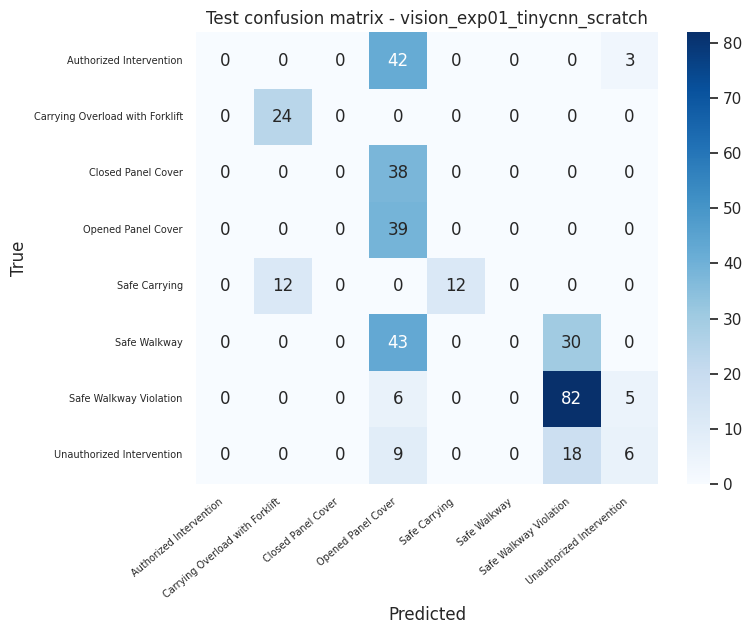

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp01_tinycnn_scratch


In [14]:
run_experiment(
    "vision_exp01_tinycnn_scratch", "Baseline CNN from scratch (no pretrained weights)",
    TinyCNN(NUM_CLASSES), base_loaders, epochs=EPOCHS_SCRATCH, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "TinyCNN", "meaning": "4 conv blocks, random initialisation"},
        {"parameter": "epochs_max", "value": EPOCHS_SCRATCH, "meaning": "Epoch limit (early stopping may end sooner)"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "AdamW learning rate"},
    ],
    extra_meta={"architecture": "TinyCNN", "pretrained": False, "freeze_backbone": False},
)

### 5.2 Experiment 2 - ResNet18, frozen backbone

,value,meaning
parameter,,
architecture,ResNet18 (ImageNet),"Backbone frozen, new linear head"
epochs_max,8,Epoch limit
lr,0.001,Head learning rate


vision_exp02_resnet18_frozen: Transfer learning - ResNet18 (frozen backbone) | epochs <= 8, lr 0.001, device cuda


epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss 1.4315 | val_loss 1.0870 | val_acc 0.6102 | val_f1_macro 0.3083  *


epoch 2/8:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 06 | train_loss 0.9067 | val_loss 0.9023 | val_acc 0.6614 | val_f1_macro 0.4595


epoch 7/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 07 | train_loss 0.9146 | val_loss 0.9030 | val_acc 0.6575 | val_f1_macro 0.4695


epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 08 | train_loss 0.8957 | val_loss 0.8987 | val_acc 0.6654 | val_f1_macro 0.4803  *
  kept epoch 8 (val macro-F1 0.4803) | test acc 0.4743 | test macro-F1 0.4162 | unsafe recall 0.9947
                                 precision    recall  f1-score   support

        Authorized Intervention      0.000     0.000     0.000        45
Carrying Overload with Forklift      0.857     1.000     0.923        24
             Closed Panel Cover      0.000     0.000     0.000        38
             Opened Panel Cover      0.228     1.000     0.371        39
                  Safe Carrying      1.000     0.833     0.909        24
                   Safe Walkway      0.000     0.000     0.000        73
         Safe Walkway Violation      0.651     0.882     0.749        93
      Unauthorized Intervention      0.500     0.303     0.377        33

                       accuracy                          0.474       369
                      macro avg      0.405     0.502     0.416       369
   

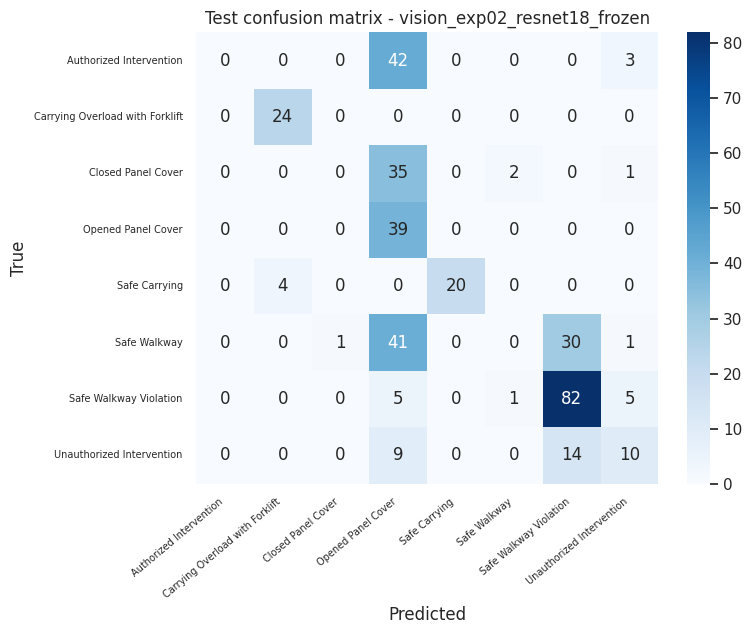

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp02_resnet18_frozen


In [15]:
run_experiment(
    "vision_exp02_resnet18_frozen", "Transfer learning - ResNet18 (frozen backbone)",
    build_resnet18(NUM_CLASSES, freeze_backbone=True), base_loaders, epochs=EPOCHS_FROZEN, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "ResNet18 (ImageNet)", "meaning": "Backbone frozen, new linear head"},
        {"parameter": "epochs_max", "value": EPOCHS_FROZEN, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "Head learning rate"},
    ],
    extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": True},
)

### 5.3 Experiment 3 - ResNet18, full fine-tune

,value,meaning
parameter,,
architecture,ResNet18 (ImageNet),Every layer trainable
epochs_max,10,Epoch limit
lr,0.00003,Low rate to keep the pretrained features


vision_exp03_resnet18_finetune: Fine-tuning - ResNet18 (full network, lower LR) | epochs <= 10, lr 3e-05, device cuda


epoch 1/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss 1.2401 | val_loss 0.8919 | val_acc 0.6772 | val_f1_macro 0.5160  *


epoch 2/10:   0%|          | 0/45 [00:10<?, ?it/s]

...

  epoch 08 | train_loss 0.4236 | val_loss 0.7560 | val_acc 0.6811 | val_f1_macro 0.6986


epoch 9/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 09 | train_loss 0.4244 | val_loss 0.7493 | val_acc 0.6772 | val_f1_macro 0.6836


epoch 10/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 10 | train_loss 0.4063 | val_loss 0.7297 | val_acc 0.6929 | val_f1_macro 0.6867
  kept epoch 7 (val macro-F1 0.7132) | test acc 0.6016 | test macro-F1 0.6292 | unsafe recall 0.8889
                                 precision    recall  f1-score   support

        Authorized Intervention      1.000     0.178     0.302        45
Carrying Overload with Forklift      1.000     1.000     1.000        24
             Closed Panel Cover      0.571     0.737     0.644        38
             Opened Panel Cover      0.435     0.769     0.556        39
                  Safe Carrying      1.000     1.000     1.000        24
                   Safe Walkway      0.460     0.315     0.374        73
         Safe Walkway Violation      0.702     0.710     0.706        93
      Unauthorized Intervention      0.373     0.576     0.452        33

                       accuracy                          0.602       369
                      macro avg      0.693     0.661     0.629       369
      

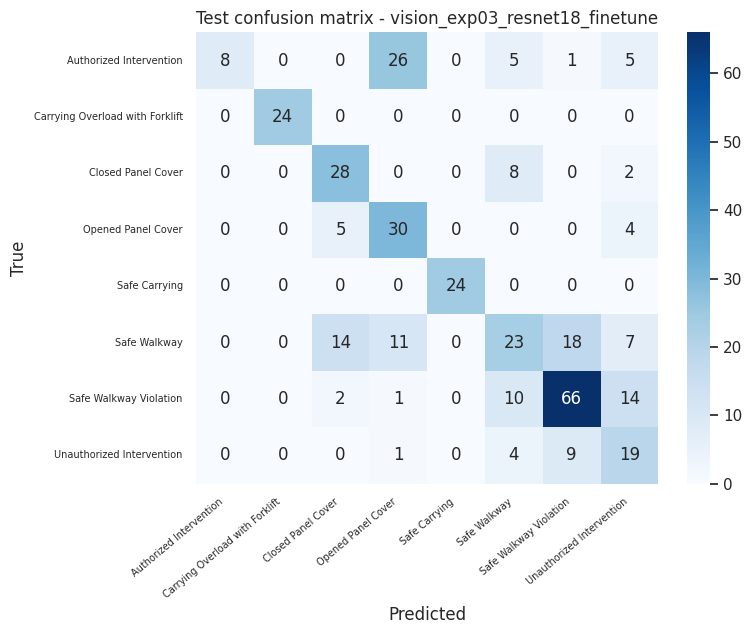

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp03_resnet18_finetune


In [16]:
run_experiment(
    "vision_exp03_resnet18_finetune", "Fine-tuning - ResNet18 (full network, lower LR)",
    build_resnet18(NUM_CLASSES, freeze_backbone=False), base_loaders, epochs=EPOCHS_FINETUNE, lr=LR_FINETUNE,
    hyperparams=[
        {"parameter": "architecture", "value": "ResNet18 (ImageNet)", "meaning": "Every layer trainable"},
        {"parameter": "epochs_max", "value": EPOCHS_FINETUNE, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_FINETUNE, "meaning": "Low rate to keep the pretrained features"},
    ],
    extra_meta={"architecture": "ResNet18", "pretrained": True, "freeze_backbone": False},
)

### 5.4 Experiment 4 - EfficientNet-B0, frozen backbone

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 144MB/s]


,value,meaning
parameter,,
architecture,EfficientNet-B0 (ImageNet),"Backbone frozen, new linear head"
epochs_max,8,Epoch limit
lr,0.001,Head learning rate


vision_exp04_efficientnet_b0_frozen: Transfer learning - EfficientNet-B0 (frozen backbone) | epochs <= 8, lr 0.001, device cuda


epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 06 | train_loss 0.8557 | val_loss 0.7986 | val_acc 0.6969 | val_f1_macro 0.5578


epoch 7/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 07 | train_loss 0.8404 | val_loss 0.7992 | val_acc 0.6850 | val_f1_macro 0.5495


epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 08 | train_loss 0.8400 | val_loss 0.8009 | val_acc 0.6890 | val_f1_macro 0.5534
  kept epoch 5 (val macro-F1 0.6125) | test acc 0.5312 | test macro-F1 0.5216 | unsafe recall 0.9630
                                 precision    recall  f1-score   support

        Authorized Intervention      0.500     0.133     0.211        45
Carrying Overload with Forklift      0.960     1.000     0.980        24
             Closed Panel Cover      0.621     0.474     0.537        38
             Opened Panel Cover      0.271     0.897     0.417        39
                  Safe Carrying      1.000     0.958     0.979        24
                   Safe Walkway      0.000     0.000     0.000        73
         Safe Walkway Violation      0.643     0.871     0.740        93
      Unauthorized Intervention      0.360     0.273     0.310        33

                       accuracy                          0.531       369
                      macro avg      0.544     0.576     0.522       369
      

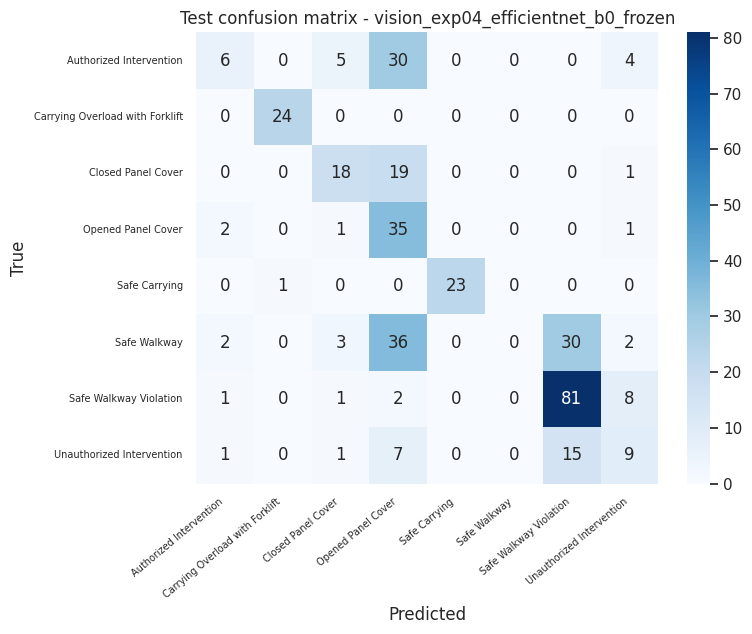

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp04_efficientnet_b0_frozen


In [17]:
run_experiment(
    "vision_exp04_efficientnet_b0_frozen", "Transfer learning - EfficientNet-B0 (frozen backbone)",
    build_efficientnet_b0(NUM_CLASSES, freeze_backbone=True), base_loaders, epochs=EPOCHS_FROZEN, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "EfficientNet-B0 (ImageNet)", "meaning": "Backbone frozen, new linear head"},
        {"parameter": "epochs_max", "value": EPOCHS_FROZEN, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "Head learning rate"},
    ],
    extra_meta={"architecture": "EfficientNet-B0", "pretrained": True, "freeze_backbone": True},
)

### 5.5 Experiment 5 - MobileNetV3-Small, frozen backbone

Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 96.7MB/s]


,value,meaning
parameter,,
architecture,MobileNetV3-Small (ImageNet),"Backbone frozen, new linear head"
epochs_max,8,Epoch limit
lr,0.001,Head learning rate


vision_exp05_mobilenet_v3_small: Edge-friendly - MobileNetV3-Small (frozen backbone) | epochs <= 8, lr 0.001, device cuda


epoch 1/8:   0%|          | 0/45 [00:00<?, ?it/s]

...

  epoch 06 | train_loss 0.7962 | val_loss 0.7852 | val_acc 0.6811 | val_f1_macro 0.5019  *


epoch 7/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 07 | train_loss 0.7820 | val_loss 0.7679 | val_acc 0.6890 | val_f1_macro 0.5373  *


epoch 8/8:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 08 | train_loss 0.7740 | val_loss 0.7646 | val_acc 0.6890 | val_f1_macro 0.5460  *
  kept epoch 8 (val macro-F1 0.5460) | test acc 0.5257 | test macro-F1 0.5056 | unsafe recall 0.9735
                                 precision    recall  f1-score   support

        Authorized Intervention      0.000     0.000     0.000        45
Carrying Overload with Forklift      1.000     1.000     1.000        24
             Closed Panel Cover      0.652     0.395     0.492        38
             Opened Panel Cover      0.284     0.974     0.439        39
                  Safe Carrying      1.000     1.000     1.000        24
                   Safe Walkway      0.125     0.014     0.025        73
         Safe Walkway Violation      0.643     0.871     0.740        93
      Unauthorized Intervention      0.367     0.333     0.349        33

                       accuracy                          0.526       369
                      macro avg      0.509     0.573     0.506       369
   

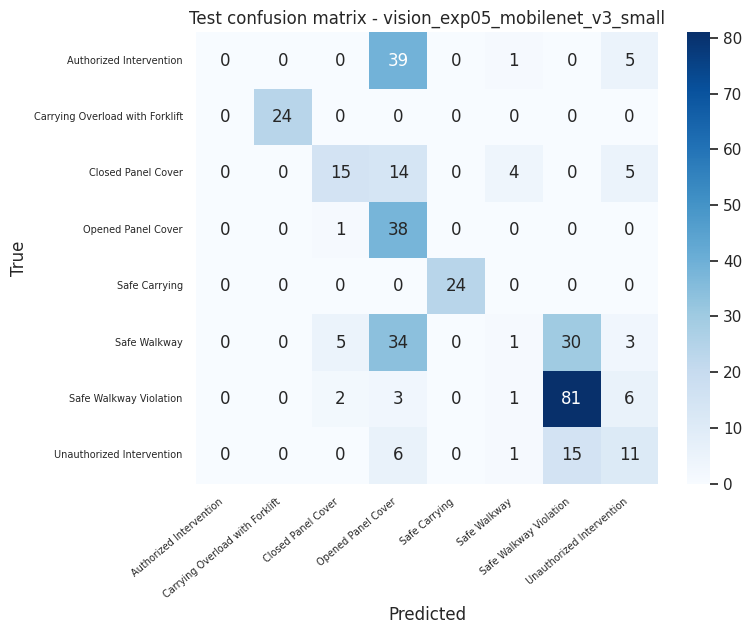

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp05_mobilenet_v3_small


In [18]:
run_experiment(
    "vision_exp05_mobilenet_v3_small", "Edge-friendly - MobileNetV3-Small (frozen backbone)",
    build_mobilenet_v3_small(NUM_CLASSES, freeze_backbone=True), base_loaders, epochs=EPOCHS_FROZEN, lr=LR_HEAD,
    hyperparams=[
        {"parameter": "architecture", "value": "MobileNetV3-Small (ImageNet)", "meaning": "Backbone frozen, new linear head"},
        {"parameter": "epochs_max", "value": EPOCHS_FROZEN, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_HEAD, "meaning": "Head learning rate"},
    ],
    extra_meta={"architecture": "MobileNetV3-Small", "pretrained": True, "freeze_backbone": True, "deployment": "edge"},
)

### 5.6 Experiment 6 - EfficientNet-B0, robust fine-tune

The imbalance is countered once, through inverse-frequency class weights in the loss, normalised so the average weight is 1. Resampling the rare classes as well would count the imbalance twice and push the model toward over-predicting them. Strong augmentation imitates other camera positions and lighting.

,train_frames,loss_weight
Authorized Intervention,59,1.678
Carrying Overload with Forklift,123,0.805
Closed Panel Cover,48,2.063
Opened Panel Cover,330,0.300
Safe Carrying,57,1.737
Safe Walkway,125,0.792
Safe Walkway Violation,449,0.221
Unauthorized Intervention,245,0.404


,value,meaning
parameter,,
architecture,EfficientNet-B0 (ImageNet),Every layer trainable
epochs_max,10,Epoch limit
lr,0.00003,Low rate to keep the pretrained features
loss,class-weighted cross-entropy,"Inverse class frequency, mean weight 1"
augmentation,"crop, flip, colour jitter, rotation",torchvision transforms


vision_exp06_efficientnet_robust: Robust fine-tune - EfficientNet-B0 + class-weighted loss + strong augmentation | epochs <= 10, lr 3e-05, device cuda


epoch 1/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 01 | train_loss 1.9488 | val_loss 1.7225 | val_acc 0.5079 | val_f1_macro 0.4016  *


...

epoch 9/10:   0%|          | 0/45 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b8c20ed2e80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    can only test a child processassert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: 
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b8c20ed2e80>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

  epoch 09 | train_loss 1.1994 | val_loss 1.1282 | val_acc 0.6181 | val_f1_macro 0.4993


epoch 10/10:   0%|          | 0/45 [00:00<?, ?it/s]

  epoch 10 | train_loss 1.1814 | val_loss 1.1158 | val_acc 0.6181 | val_f1_macro 0.4993
  kept epoch 7 (val macro-F1 0.5079) | test acc 0.4688 | test macro-F1 0.4439 | unsafe recall 0.9841
                                 precision    recall  f1-score   support

        Authorized Intervention      0.200     0.022     0.040        45
Carrying Overload with Forklift      1.000     1.000     1.000        24
             Closed Panel Cover      0.000     0.000     0.000        38
             Opened Panel Cover      0.215     0.949     0.351        39
                  Safe Carrying      1.000     1.000     1.000        24
                   Safe Walkway      0.000     0.000     0.000        73
         Safe Walkway Violation      0.649     0.774     0.706        93
      Unauthorized Intervention      0.455     0.455     0.455        33

                       accuracy                          0.469       369
                      macro avg      0.440     0.525     0.444       369
      

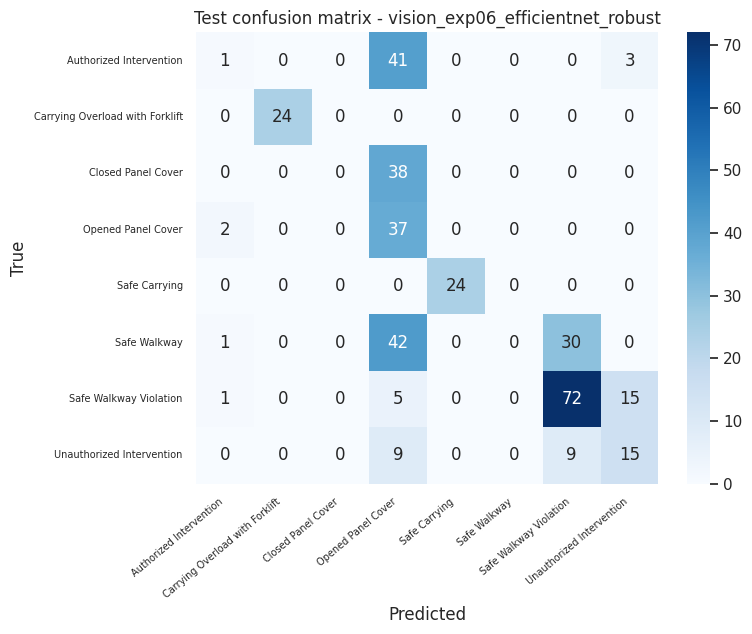

[SAVE] /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/vision_exp06_efficientnet_robust


In [19]:
train_counts = FRAMES["train"]["label_idx"].value_counts().reindex(range(NUM_CLASSES), fill_value=0)
inverse = 1.0 / train_counts.clip(lower=1).to_numpy(dtype=np.float32)
class_weights = torch.tensor(inverse / inverse.mean(), dtype=torch.float32)
save_table(pd.DataFrame({"train_frames": train_counts.to_numpy(), "loss_weight": class_weights.numpy().round(3)}, index=CLASS_NAMES), "exp06_class_weights")

run_experiment(
    "vision_exp06_efficientnet_robust", "Robust fine-tune - EfficientNet-B0 + class-weighted loss + strong augmentation",
    build_efficientnet_b0(NUM_CLASSES, freeze_backbone=False), make_loaders(FRAMES, strong_train_tfms),
    epochs=EPOCHS_FINETUNE, lr=LR_FINETUNE, class_weights=class_weights,
    hyperparams=[
        {"parameter": "architecture", "value": "EfficientNet-B0 (ImageNet)", "meaning": "Every layer trainable"},
        {"parameter": "epochs_max", "value": EPOCHS_FINETUNE, "meaning": "Epoch limit"},
        {"parameter": "lr", "value": LR_FINETUNE, "meaning": "Low rate to keep the pretrained features"},
        {"parameter": "loss", "value": "class-weighted cross-entropy", "meaning": "Inverse class frequency, mean weight 1"},
        {"parameter": "augmentation", "value": "crop, flip, colour jitter, rotation", "meaning": "torchvision transforms"},
    ],
    extra_meta={"architecture": "EfficientNet-B0", "pretrained": True, "freeze_backbone": False,
                "class_weights": class_weights.tolist(), "strong_augmentation": True},
)

## 6. Compare, promote and evaluate SAFE/UNSAFE

### 6.1 Comparison

The ledger holds one row per experiment. Experiments are ranked by **best validation macro-F1**, the only score used to choose. The test columns show how each model does on unseen clips. Where the validation and test rankings disagree, remember that the validation set is small: about 85 clips.

,approach,best_val_f1_macro,best_epoch,epochs_run,test_accuracy,test_f1_macro,test_f1_weighted,test_binary_accuracy,test_unsafe_recall,test_unsafe_precision,test_safe_recall,lr,elapsed_sec
experiment_id,,,,,,,,,,,,,
vision_exp03_resnet18_finetune,"Fine-tuning - ResNet18 (full network, lower LR)",0.7132,7,10,0.6016,0.6292,0.5842,0.7534,0.8889,0.7059,0.6111,0.000,109.6823
vision_exp04_efficientnet_b0_frozen,Transfer learning - EfficientNet-B0 (frozen ba...,0.6125,5,8,0.5312,0.5216,0.4666,0.6477,0.9630,0.5967,0.3167,0.001,113.0627
vision_exp05_mobilenet_v3_small,Edge-friendly - MobileNetV3-Small (frozen back...,0.5460,8,8,0.5257,0.5056,0.4497,0.6341,0.9735,0.5860,0.2778,0.001,82.1608
vision_exp06_efficientnet_robust,Robust fine-tune - EfficientNet-B0 + class-wei...,0.5079,7,10,0.4688,0.4439,0.3906,0.5745,0.9841,0.5471,0.1444,0.000,116.6522
vision_exp02_resnet18_frozen,Transfer learning - ResNet18 (frozen backbone),0.4803,8,8,0.4743,0.4162,0.3809,0.5718,0.9947,0.5449,0.1278,0.001,82.7159
vision_exp01_tinycnn_scratch,Baseline CNN from scratch (no pretrained weights),0.4032,8,12,0.4417,0.3523,0.3417,0.5447,1.0000,0.5294,0.0667,0.001,142.3681


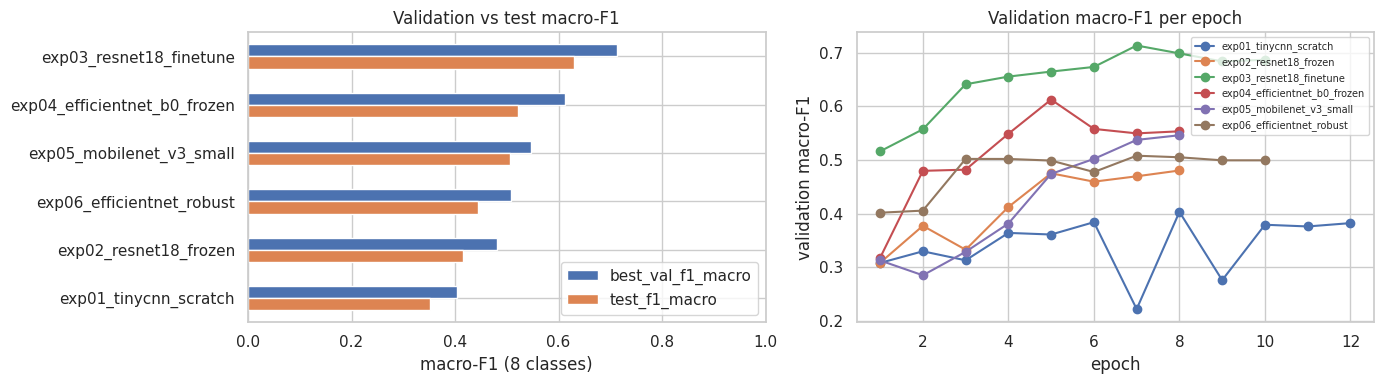

In [20]:
EXPERIMENT_IDS = [
    "vision_exp01_tinycnn_scratch", "vision_exp02_resnet18_frozen", "vision_exp03_resnet18_finetune",
    "vision_exp04_efficientnet_b0_frozen", "vision_exp05_mobilenet_v3_small", "vision_exp06_efficientnet_robust",
]
ledger = pd.read_csv(LEDGER_PATH)
comparison = ledger[ledger["experiment_id"].isin(EXPERIMENT_IDS)].sort_values("best_val_f1_macro", ascending=False).set_index("experiment_id")
save_table(comparison.drop(columns=["timestamp_utc"]).round(4), "experiment_comparison")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
short = [i.replace("vision_", "") for i in comparison.index]
comparison[["best_val_f1_macro", "test_f1_macro"]].set_axis(short).plot.barh(ax=axes[0])
axes[0].invert_yaxis()
axes[0].set(xlabel="macro-F1 (8 classes)", title="Validation vs test macro-F1", xlim=(0, 1))
for exp_id, result in EXPERIMENT_RESULTS.items():
    axes[1].plot(result["history"]["epoch"], result["history"]["val_f1_macro"], marker="o", label=exp_id.replace("vision_", ""))
axes[1].set(xlabel="epoch", ylabel="validation macro-F1", title="Validation macro-F1 per epoch")
axes[1].legend(fontsize=7)
save_figure("experiment_comparison")

### 6.2 Promote the validation winner

The winner's weights are copied to `best.pt` with its metadata and a model card. The test set did not influence the choice.

In [21]:
winner_id = comparison.index[0]
src_dir = MODELS_DIR / winner_id
shutil.copy2(src_dir / "model.pt", MODELS_DIR / "best.pt")
winner_meta = json.loads((src_dir / "metadata.json").read_text())
winner_meta.update({"promoted_from": winner_id, "selection_metric": "best_val_f1_macro", "selection_value": float(comparison.loc[winner_id, "best_val_f1_macro"])})
(MODELS_DIR / "metadata.json").write_text(json.dumps(winner_meta, indent=2, default=to_json_safe))

test = winner_meta["test_metrics"]
(MODELS_DIR / "model_card.md").write_text(f"""# SAMS safe/unsafe behaviour classifier

- **Status:** exploratory; not loaded by the live SAMS services
- **Model:** {winner_id} ({winner_meta['approach']})
- **Dataset:** {HF_REPO}, published train/test split; validation = {VAL_FRACTION:.0%} of each class's training clips
- **Input:** RGB frame resized to {IMG_SIZE}x{IMG_SIZE}, ImageNet normalisation
- **Classes:** {', '.join(CLASS_NAMES)}
- **Selected on:** validation macro-F1 = {winner_meta['selection_value']:.3f} (epoch {winner_meta['best_epoch']})
- **Test, 8 classes:** accuracy {test['accuracy']:.3f}, macro-F1 {test['f1_macro']:.3f}
- **Test, SAFE/UNSAFE:** accuracy {test['binary_accuracy']:.3f}, unsafe recall {test['unsafe_recall']:.3f}, unsafe precision {test['unsafe_precision']:.3f}
- **Limits:** one facility; single frames cannot see context (who is authorised); see Section 7 of notebooks/01_vision_safe_unsafe.ipynb
""")
print("Promoted", winner_id, "to", MODELS_DIR / "best.pt")

Promoted vision_exp03_resnet18_finetune to /content/drive/MyDrive/SAMS/models/vision/safe_unsafe/best.pt


### 6.3 Winner in detail

Per-class F1 shows which behaviours the winner can and cannot tell apart. The SAFE/UNSAFE table folds the eight-class confusion matrix into the two groups SAMS would act on. A frame counts as caught when the model predicts any unsafe class for an unsafe frame, even if it names the wrong one.

In [22]:
cm = np.array(test["confusion_matrix"])
per_class = pd.DataFrame({
    "group": ["UNSAFE" if c in UNSAFE_CLASSES else "SAFE" for c in CLASS_NAMES],
    "test_frames": cm.sum(axis=1),
    "recall": np.diag(cm) / cm.sum(axis=1).clip(min=1),
    "f1": [test["f1_per_class"][c] for c in CLASS_NAMES],
    "most_confused_with": [CLASS_NAMES[int(np.argmax(np.where(np.arange(NUM_CLASSES) == i, -1, cm[i])))] for i in range(NUM_CLASSES)],
}, index=CLASS_NAMES)
save_table(per_class.sort_values("f1").round(3), "winner_per_class")

is_unsafe = np.isin(np.arange(NUM_CLASSES), UNSAFE_IDX)
binary_cm = pd.DataFrame(
    [[cm[np.ix_(~is_unsafe, ~is_unsafe)].sum(), cm[np.ix_(~is_unsafe, is_unsafe)].sum()],
     [cm[np.ix_(is_unsafe, ~is_unsafe)].sum(), cm[np.ix_(is_unsafe, is_unsafe)].sum()]],
    index=["true SAFE", "true UNSAFE"], columns=["pred SAFE", "pred UNSAFE"],
)
save_table(binary_cm, "winner_safe_unsafe_confusion")
save_table(comparison[["test_binary_accuracy", "test_unsafe_recall", "test_unsafe_precision", "test_safe_recall"]].round(3), "safe_unsafe_by_experiment")

,group,test_frames,recall,f1,most_confused_with
Authorized Intervention,SAFE,45,0.178,0.302,Opened Panel Cover
Safe Walkway,SAFE,73,0.315,0.374,Safe Walkway Violation
Unauthorized Intervention,UNSAFE,33,0.576,0.452,Safe Walkway Violation
Opened Panel Cover,UNSAFE,39,0.769,0.556,Closed Panel Cover
Closed Panel Cover,SAFE,38,0.737,0.644,Safe Walkway
Safe Walkway Violation,UNSAFE,93,0.710,0.706,Unauthorized Intervention
Carrying Overload with Forklift,UNSAFE,24,1.000,1.000,Authorized Intervention
Safe Carrying,SAFE,24,1.000,1.000,Authorized Intervention


,pred SAFE,pred UNSAFE
true SAFE,110,70
true UNSAFE,21,168


,test_binary_accuracy,test_unsafe_recall,test_unsafe_precision,test_safe_recall
experiment_id,,,,
vision_exp03_resnet18_finetune,0.753,0.889,0.706,0.611
vision_exp04_efficientnet_b0_frozen,0.648,0.963,0.597,0.317
vision_exp05_mobilenet_v3_small,0.634,0.974,0.586,0.278
vision_exp06_efficientnet_robust,0.575,0.984,0.547,0.144
vision_exp02_resnet18_frozen,0.572,0.995,0.545,0.128
vision_exp01_tinycnn_scratch,0.545,1.000,0.529,0.067


PosixPath('/content/drive/MyDrive/SAMS/results/vision/safe_unsafe/safe_unsafe_by_experiment.csv')

## 7. Findings, limitations and relevance to SAMS

### What the experiments show

- **Fine-tuning is what makes pretraining pay off.** Frozen ImageNet backbones perform at roughly the level of a small network trained from scratch. Adapting the features to the domain by fine-tuning gives the largest step. The behaviours depend on scene details that generic features do not emphasise.
- **Performance is uneven across classes.** Classes with a distinctive scene, such as forklift loads or carrying, are recognised easily. Pairs that look alike in a single frame are not, above all **authorized vs unauthorized intervention**: the difference is who is allowed to act, which is not visible in the image.
- **The SAFE/UNSAFE view is the meaningful one for SAMS.** Many eight-class errors stay inside the right group, so the share of unsafe frames caught is clearly higher than the eight-class accuracy.

### Limitations

1. **One facility.** Every clip comes from the same site, cameras and people. Classes with a distinctive scene may be recognised by the place rather than the behaviour, and accuracy on another site is unknown.
2. **Single frames.** Several classes are defined by an action or by context, which a single frame cannot capture. A clip-level model (several frames, or video features) would be the natural next design.
3. **Small validation and test sets.** About 85 validation clips and 125 test clips. Rare classes have 8–15 test clips, so their per-class scores move in large steps, and close rankings between experiments are within noise.
4. **Frames from a clip are correlated.** Frames are kept together within each split, but the three frames from one clip still count as three test samples, which overstates the effective test size.

### Relevance to SAMS

The live system does not use this model. SAMS judges risk from measurable quantities on its own camera: person, PPE, distance to the machine, pose, motion and falls. These transfer to a new site, whereas behaviour classes learned in another facility do not. This notebook stands as the project's transfer-learning study. If behaviour classification becomes a SAMS feature, it should be trained on clips recorded on site, with classes defined for the SAMS machine, and evaluated as SAFE/UNSAFE with unsafe recall as the headline metric.